# INFO 367 Group 4: Can AI Read an Earnings Release?

**Team:** four students in INFO 367 (Applied Large Language Models for Business, Montclair State University, Fall 2026). I, Muhammad Nabeel, led the project. My teammates' names are left out of this public copy.

### What we're doing
We have 291 earnings press releases. Each one is labeled **up**, **down** or **flat** based on how the stock did against the S&P 500 the next day. Up means it beat the S&P 500 by more than 3%, down means it did worse by more than 3%, and flat is anything in between. We test if a model can read just the press release and guess the label. We try five models on the same test set and see which one gets it right most often.

### Who did what
* **Nabeel:** Steps 1, 2, 4, 5, 6, 15 and the final run
* **Teammate A:** Steps 7, 9, 10, 11, 12 (ran Gemini on Oct 25)
* **Teammates A and B:** Steps 8 and 13
* **Teammate B:** Step 14
* **Teammate C:** Step 3

### How to run it
1. Click **Runtime**, then **Run all**.
2. At Step 2 it asks for files. Pick these 3 at the same time: `group4_dataset.csv`, `group4_predictions.csv` and `group4_call_log.csv`.
3. That's it. It does **not** call Gemini again. It reads the 352 answers saved on Oct 25, so the results are the same every time.

### Model and cost
* Model: Gemini Flash (`gemini-3.7-flash`), the same one from Week 5.
* The Oct 25 run made 352 calls. At paid rates that is \$4.93. We have a \$5 limit and a 387 call cap in Step 7 so it can't run up a bill.


## Step 1: Setup (Nabeel)

In [1]:
# Step 1: tools, the Gemini key, the model and the price list
import json, os, random, re, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 367                      # same seed everywhere, so every run gives the same split and examples
random.seed(SEED); np.random.seed(SEED)

LABELS = ["up", "down", "flat"]  # our three labels, always in this order

# This run only reads the answers a teammate saved on Oct 25, so it never calls Gemini.
# To call Gemini again, set RUN_GEMINI = True and turn on your key in Colab Secrets.
RUN_GEMINI = False
API_KEY = None
if RUN_GEMINI:
    try:
        from google.colab import userdata
        API_KEY = userdata.get("GEMINI_API_KEY")   # never type the key into a cell
    except Exception:
        API_KEY = os.environ.get("GEMINI_API_KEY")

client, FLASH = None, "gemini-3.7-flash"
if API_KEY:
    from google import genai
    from google.genai import types, errors as genai_errors
    client = genai.Client(api_key=API_KEY)
    print("Gemini key found. Model:", FLASH)
else:
    print("Using the saved Gemini answers (group4_predictions.csv). No new calls.")

# USD per 1 million tokens. Gemini Flash paid price through Dec 31, 2026 (ai.google.dev pricing page).
# On the free tier we pay $0. These rates only show what it WOULD cost with billing on.
# Thinking tokens (if the model uses them) are billed as output.
RATES = {"input": 0.75, "output": 3.75}
print("Rates per 1M tokens:", RATES)

Matplotlib is building the font cache; this may take a moment.


Using the saved Gemini answers (group4_predictions.csv). No new calls.
Rates per 1M tokens: {'input': 0.75, 'output': 3.75}


## Step 2: Load the data (Nabeel)

We take out 9 records that aren't earnings releases.

In [2]:
# Step 2: load the dataset and remove the records that are not earnings releases
DATA_FILE = "group4_dataset.csv"

NEEDED = [DATA_FILE, "group4_predictions.csv", "group4_call_log.csv"]
missing = [f for f in NEEDED if not os.path.exists(f)]
if missing:
    try:
        from google.colab import files
        print("Pick these 3 files at the same time:", ", ".join(missing))
        files.upload()
    except ImportError:
        pass
missing = [f for f in NEEDED if not os.path.exists(f)]
if missing:
    raise FileNotFoundError(f"Still missing: {missing}. Upload them with the folder icon on the left, then run this step again.")

raw = pd.read_csv(DATA_FILE)
print("Records in the file:", len(raw))

# Records that are not earnings press releases. Each one has the reason next to it.
NOT_EARNINGS = {
    "R003": "spin-off announcement",
    "R015": "investor update slides",
    "R044": "a subsidiary's financial statements",
    "R079": "CFO change",
    "R081": "investor day slides",
    "R109": "supplemental tables only",
    "R151": "supplemental tables only",
    "R162": "filing code, no press release",
    "R212": "webinar notice",
}
removed = raw[raw.record_id.isin(NOT_EARNINGS)]
df = raw[~raw.record_id.isin(NOT_EARNINGS)].reset_index(drop=True)

# Quick checks the rubric asks about: no empty text, no duplicates, one label each
assert df.text.str.strip().str.len().gt(0).all(), "found an empty text"
assert not df.record_id.duplicated().any(), "found a duplicate record_id"
assert not df.text.duplicated().any(), "found two identical texts"
assert set(df.label) <= set(LABELS), "found a label that isn't up, down or flat"

print(f"Removed {len(removed)} records that are not earnings releases:")
for rid, why in NOT_EARNINGS.items():
    if rid in set(removed.record_id):
        print(f"  {rid}: {why}")
print("Records we use:", len(df))

Records in the file: 300
Removed 9 records that are not earnings releases:
  R003: spin-off announcement
  R015: investor update slides
  R044: a subsidiary's financial statements
  R079: CFO change
  R081: investor day slides
  R109: supplemental tables only
  R151: supplemental tables only
  R162: filing code, no press release
  R212: webinar notice
Records we use: 291


## Step 3: Look at the data (teammate)

Check the chart and the examples look right.

       records  percent
label                  
up          83     28.5
down        73     25.1
flat       135     46.4 



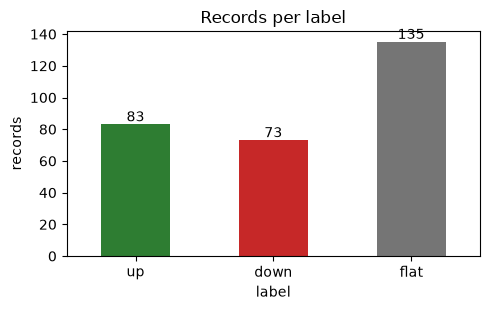

Text length in words (median and 90th percentile):
       median    p90
label               
up      400.0  400.0
down    400.0  400.0
flat    400.0  400.0 

=== Two 'up' examples ===
[R188] FEDERAL REALTY INVESTMENT TRUST SUPPLEMENTAL INFORMATION March 31, 2026 TABLE OF CONTENTS 1 First Quarter 2026 Earnings Press Release 3 2 Financial Highlights Consolidated Income Statements 7 Consolidated Balance Sheets 8 Funds From Operations 9 Other Supplemental Information 10 Components of Rental...

[R021] October 23, 2025 Dow reports third quarter 2025 results 3Q25 FINANCIAL HIGHLIGHTS • Net sales were $10.0 billion, down 8% year-over-year, reflecting declines in all operating segments. Sequentially, net sales were down 1%, as gains in Industrial Intermediates & Infrastructure were more than offset b...

=== Two 'down' examples ===
[R158] EXHIBIT 99.1 Las Vegas Sands Reports First Quarter 2026 Results For the quarter ended March 31, 2026 • Net Revenue Increased 25.3% to $3.59 billion • Net Inc

In [3]:
# Step 3: label counts, a bar chart, text length by label, and two examples per label
counts = df.label.value_counts().reindex(LABELS)
summary = pd.DataFrame({"records": counts, "percent": (counts / len(df) * 100).round(1)})
print(summary.to_string(), "\n")

ax = counts.plot.bar(color=["#2E7D32", "#C62828", "#757575"], figsize=(5, 3.2), rot=0)
ax.set_title("Records per label"); ax.set_ylabel("records")
for i, v in enumerate(counts):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout(); plt.show()

df["words"] = df.text.str.split().str.len()
length = df.groupby("label").words.agg(median="median", p90=lambda s: s.quantile(0.9)).reindex(LABELS)
print("Text length in words (median and 90th percentile):")
print(length.to_string(), "\n")

for lab in LABELS:
    print(f"=== Two '{lab}' examples ===")
    for r in df[df.label == lab].sample(2, random_state=SEED).itertuples():
        print(f"[{r.record_id}] {r.text[:300]}...\n")

## Step 4: Split into train and test (Nabeel)

70% train, 30% test. Same split for every model.

In [4]:
# Step 4: ONE stratified 70/30 split, used by every model
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.3, stratify=df.label, random_state=SEED)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

pd.concat([train_df[["record_id"]].assign(split="train"),
           test_df[["record_id"]].assign(split="test")]).to_csv("group4_split_ids.csv", index=False)

print(f"train {len(train_df)} | test {len(test_df)}")
print(pd.DataFrame({"train": train_df.label.value_counts(), "test": test_df.label.value_counts()}).reindex(LABELS).to_string())
assert not set(train_df.record_id) & set(test_df.record_id), "a record is in both train and test"

train 203 | test 88
       train  test
label             
up        58    25
down      51    22
flat      94    41


## Step 5: Model 1, the basic model (Nabeel)

TF-IDF + logistic regression.

In [5]:
# Step 5: TF-IDF + logistic regression, tuned with cross-validation on TRAIN only
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold

pipe = Pipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True, strip_accents="unicode", stop_words="english")),
    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced")),
])
grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3],
    "clf__C": [0.5, 1.0, 4.0],
}
search = GridSearchCV(pipe, grid, scoring="f1_macro",
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
t0 = time.perf_counter()
search.fit(train_df.text, train_df.label)
train_seconds = time.perf_counter() - t0
classical = search.best_estimator_

print("Settings we used:", search.best_params_)
print(f"Cross-validated macro F1 on train: {search.best_score_:.3f}  (trained in {train_seconds:.1f} s)")

Settings we used: {'clf__C': 0.5, 'tfidf__min_df': 3, 'tfidf__ngram_range': (1, 1)}
Cross-validated macro F1 on train: 0.384  (trained in 4.4 s)


### Top words for each label

In [6]:
# Top 12 words for each label, and a leakage check
vocab = np.array(classical.named_steps["tfidf"].get_feature_names_out())
coefs = classical.named_steps["clf"].coef_
for i, lab in enumerate(classical.named_steps["clf"].classes_):
    top = vocab[np.argsort(coefs[i])[::-1][:12]]
    print(f"{lab:>5}: {', '.join(top)}")
    if lab in top:
        print(f"   WARNING: the word '{lab}' is a top word for its own label. Check for leakage.")

 down: revenue, 53, investor, 29, 85, relations, march, buy, segment, thousands, q4, week
 flat: higher, investment, prior, corporation, energy, sales, combined, companies, jones, ameren, loews, estate
   up: grew, organic, second, 2026, volume, high, organically, growth, eps, margin, expect, points


## Step 6: Score the basic model (Nabeel)

=== TF-IDF + logistic regression ===
              precision    recall  f1-score   support

          up      0.296     0.320     0.308        25
        down      0.367     0.500     0.423        22
        flat      0.677     0.512     0.583        41

    accuracy                          0.455        88
   macro avg      0.447     0.444     0.438        88
weighted avg      0.491     0.455     0.465        88



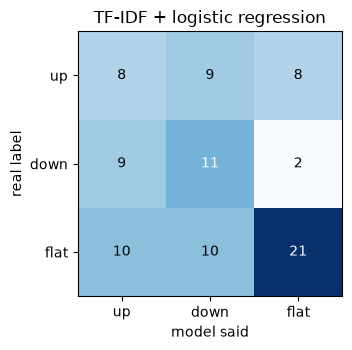

In [7]:
# Step 6: one scorer for every model
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

RESULTS = []        # one row per model for the final table
ALL_PREDS = {}      # every model's predictions on the test set

def score(name, y_pred):
    """Score one model on the test set. Invalid answers stay in and count as wrong."""
    y_true = list(test_df.label)
    y_pred = [p if p in LABELS else "INVALID" for p in y_pred]
    ALL_PREDS[name] = y_pred
    f1s = f1_score(y_true, y_pred, labels=LABELS, average=None, zero_division=0)
    row = {"Model": name,
           "Accuracy": round(accuracy_score(y_true, y_pred), 3),
           "Macro F1": round(f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0), 3),
           **{f"F1: {lab}": round(f, 3) for lab, f in zip(LABELS, f1s)},
           "Invalid answers": sum(p == "INVALID" for p in y_pred)}
    RESULTS[:] = [r for r in RESULTS if r["Model"] != name] + [row]
    print(f"=== {name} ===")
    print(classification_report(y_true, y_pred, labels=LABELS, digits=3, zero_division=0))
    return row

def show_confusion(name):
    """Rows are the real label, columns are what the model said."""
    cm = confusion_matrix(list(test_df.label), ALL_PREDS[name], labels=LABELS)
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xlabel("model said"); ax.set_ylabel("real label"); ax.set_title(name)
    plt.tight_layout(); plt.show()

score("TF-IDF + logistic regression", classical.predict(test_df.text))
show_confusion("TF-IDF + logistic regression")

## Step 7: Gemini setup (teammate)

In [8]:
# Step 7: call log, call cap, spend ceiling, and the one function that talks to Gemini
N_TEST = len(test_df)
CALL_CAP = int(4 * N_TEST * 1.10)     # 4 Gemini settings x the test set, plus 10% room for retries
SPEND_CEILING_USD = 5.00              # the full run is about $2.50 at paid rates. Stops a runaway loop.
CALL_LOG = []

def spent():
    return sum(r["cost_usd"] for r in CALL_LOG)

def cost_of(in_tok, out_tok):
    return in_tok / 1e6 * RATES["input"] + out_tok / 1e6 * RATES["output"]

def check_budget(est_in_tok, est_out_tok=20):
    if len(CALL_LOG) >= CALL_CAP:
        raise RuntimeError(f"Call cap reached ({CALL_CAP}). Check the step before running it again.")
    if spent() + cost_of(est_in_tok, est_out_tok) > SPEND_CEILING_USD:
        raise RuntimeError(f"Spend ceiling ${SPEND_CEILING_USD:.2f} would be passed (spent ${spent():.4f}).")

# The answer can ONLY be one of our three labels (structured output with an enum, like Week 4)
SCHEMA = {"type": "OBJECT",
          "properties": {"label": {"type": "STRING", "enum": LABELS}},
          "required": ["label"]}

def ask_gemini(prompt, setting, max_tries=6):
    """One call: check the budget, send, retry if Gemini is busy, log it, return (label, raw text)."""
    check_budget(est_in_tok=len(prompt) // 4)
    # No temperature, top_p or top_k: Gemini removed them in 2026
    cfg = types.GenerateContentConfig(response_mime_type="application/json", response_schema=SCHEMA)
    for attempt in range(max_tries):
        t0 = time.perf_counter()
        try:
            resp = client.models.generate_content(model=FLASH, contents=prompt, config=cfg)
        except (genai_errors.ServerError, genai_errors.ClientError) as e:
            code = getattr(e, "code", None)
            if code == 429 or (code or 0) >= 500:
                time.sleep(min(60, 2 ** attempt + random.random()))
                continue
            raise
        ms = (time.perf_counter() - t0) * 1000
        u = resp.usage_metadata
        in_tok = u.prompt_token_count or 0
        out_tok = (u.candidates_token_count or 0) + (getattr(u, "thoughts_token_count", 0) or 0)
        CALL_LOG.append({"setting": setting, "model": FLASH, "in_tok": in_tok, "out_tok": out_tok,
                         "cost_usd": cost_of(in_tok, out_tok), "latency_ms": round(ms),
                         "attempts": attempt + 1})
        raw = resp.text or ""
        try:
            label = json.loads(raw)["label"]
        except Exception:
            label = "INVALID"          # counted as wrong, never dropped
        return label, raw
    return "INVALID", f"gave up after {max_tries} tries"

print(f"Test set {N_TEST} records | call cap {CALL_CAP} | spend ceiling ${SPEND_CEILING_USD:.2f}")

Test set 88 records | call cap 387 | spend ceiling $5.00


## Step 8: The Gemini prompt (teammates)

You labeled the 30, so check these label definitions match how you labeled. If something is off, fix the wording here.

In [9]:
# Step 8: the label definitions (same as the labeling guide) and the zero-shot prompt
LABEL_DEFS = """- up: after this release, the stock beat the S&P 500 by more than 3% from the close before the release to the close of the next trading day
- down: after this release, the stock did worse than the S&P 500 by more than 3% over the same window
- flat: the stock finished within 3% of the S&P 500 over the same window"""

PROMPT_ZERO = """You read company earnings press releases and predict how the stock reacted.

Choose the ONE label that best describes how the stock moved compared to the S&P 500,
from the close right before the release to the close of the next trading day.

Labels:
{defs}

Press release:
{text}

Return JSON only."""

PROMPT_FEW = """You read company earnings press releases and predict how the stock reacted.

Choose the ONE label that best describes how the stock moved compared to the S&P 500,
from the close right before the release to the close of the next trading day.

Labels:
{defs}

Here are some past press releases with the real label:
{examples}

Press release:
{text}

Return JSON only."""

print(PROMPT_ZERO.format(defs=LABEL_DEFS, text=test_df.text[0][:500] + " ..."))

You read company earnings press releases and predict how the stock reacted.

Choose the ONE label that best describes how the stock moved compared to the S&P 500,
from the close right before the release to the close of the next trading day.

Labels:
- up: after this release, the stock beat the S&P 500 by more than 3% from the close before the release to the close of the next trading day
- down: after this release, the stock did worse than the S&P 500 by more than 3% over the same window
- flat: the stock finished within 3% of the S&P 500 over the same window

Press release:
.01 Contacts: Investors Media Kendra Goodenough Kali Fry Intuit Inc. Intuit Inc. 650-944-3663 650-944-3036 kendra_goodenough@intuit.com kali_fry@intuit.com Intuit Reports Fourth Quarter and Full Year Fiscal 2026 Results; Sets Fiscal 2027 Guidance Fourth-quarter revenue grew 14 percent, full year fiscal 2026 revenue grew 14 percent MOUNTAIN VIEW, Calif. - Aug. 25, 2026 - Intuit Inc. (Nasdaq: INTU) the global financia

## Step 9: Pick the examples, from train only (teammate)

In [10]:
# Step 9: nested few-shot examples, from TRAIN only, with a fixed seed
pool = {lab: train_df[train_df.label == lab].sample(frac=1, random_state=SEED).reset_index(drop=True)
        for lab in LABELS}

def build_examples(k):
    """k examples per label. Take the first k from each shuffled pool, so 1 is inside 5 is inside 10."""
    rows = []
    for i in range(k):                       # mix the labels: up, down, flat, up, down, flat...
        for lab in LABELS:
            rows.append(pool[lab].iloc[i])
    return rows

SHOTS = {k: build_examples(k) for k in (1, 5, 10)}

def examples_text(rows):
    return "\n\n".join(f'Press release: {r.text}\n{{"label": "{r.label}"}}' for r in rows)

# Guards: nested, and nothing from the test set
ids = {k: [r.record_id for r in v] for k, v in SHOTS.items()}
assert set(ids[1]) <= set(ids[5]) <= set(ids[10]), "examples are not nested"
assert not set(ids[10]) & set(test_df.record_id), "an example leaked from the test set"
for k in (1, 5, 10):
    print(f"k={k:>2}: {len(ids[k])} examples -> {ids[k][:6]}{' ...' if len(ids[k]) > 6 else ''}")

k= 1: 3 examples -> ['R083', 'R041', 'R119']
k= 5: 15 examples -> ['R083', 'R041', 'R119', 'R033', 'R132', 'R101'] ...
k=10: 30 examples -> ['R083', 'R041', 'R119', 'R033', 'R132', 'R101'] ...


## Step 10: Run Gemini, Models 2 to 5 (teammate)

Only a teammate runs this. It takes a while. If it stops, just run it again and it picks up where it left off. When it's done, share `group4_predictions.csv` with the group.

In [11]:
# Step 10: run zero-shot and few-shot (k = 1, 5, 10), saving every answer as we go
PRED_FILE = "group4_predictions.csv"
LOG_FILE = "group4_call_log.csv"
SETTINGS = {"Gemini zero-shot": 0, "Gemini few-shot, k = 1": 1,
            "Gemini few-shot, k = 5": 5, "Gemini few-shot, k = 10": 10}

saved = pd.read_csv(PRED_FILE) if os.path.exists(PRED_FILE) else \
        pd.DataFrame(columns=["setting", "record_id", "label", "raw"])
if os.path.exists(LOG_FILE):
    CALL_LOG[:] = pd.read_csv(LOG_FILE).to_dict("records")

for setting, k in SETTINGS.items():
    done = set(saved.loc[saved.setting == setting, "record_id"])
    todo = test_df[~test_df.record_id.isin(done)]
    if todo.empty:
        print(f"{setting}: all {N_TEST} answers already saved")
        continue
    if client is None:
        raise RuntimeError(f"{setting}: {len(todo)} answers missing. A teammate runs this step. "
                           f"Upload {PRED_FILE} from that teammate, then Run all again.")
    ex = examples_text(SHOTS[k]) if k else ""
    print(f"{setting}: sending {len(todo)} releases")
    for n, r in enumerate(todo.itertuples(), 1):
        prompt = (PROMPT_FEW.format(defs=LABEL_DEFS, examples=ex, text=r.text) if k
                  else PROMPT_ZERO.format(defs=LABEL_DEFS, text=r.text))
        label, raw = ask_gemini(prompt, setting)
        saved = pd.concat([saved, pd.DataFrame([{"setting": setting, "record_id": r.record_id,
                                                  "label": label, "raw": raw}])], ignore_index=True)
        saved.to_csv(PRED_FILE, index=False)               # save after EVERY call
        pd.DataFrame(CALL_LOG).to_csv(LOG_FILE, index=False)
        if n % 20 == 0 or n == len(todo):
            print(f"  {n}/{len(todo)}  spent so far ${spent():.4f}")

print("\nSaved answers per setting:")
print(saved.setting.value_counts().reindex(SETTINGS).to_string())

Gemini zero-shot: all 88 answers already saved
Gemini few-shot, k = 1: all 88 answers already saved
Gemini few-shot, k = 5: all 88 answers already saved
Gemini few-shot, k = 10: all 88 answers already saved

Saved answers per setting:
setting
Gemini zero-shot           88
Gemini few-shot, k = 1     88
Gemini few-shot, k = 5     88
Gemini few-shot, k = 10    88


## Step 11: Score the Gemini models (teammate)

In [12]:
# Step 11: score each Gemini setting from the saved answers
saved = pd.read_csv(PRED_FILE)
for setting in SETTINGS:
    got = saved[saved.setting == setting].drop_duplicates("record_id", keep="last").set_index("record_id").label
    preds = [got.get(rid, "INVALID") for rid in test_df.record_id]   # a missing answer counts as wrong
    score(setting, preds)

=== Gemini zero-shot ===
              precision    recall  f1-score   support

          up      0.500     0.680     0.576        25
        down      0.467     0.636     0.538        22
        flat      0.833     0.488     0.615        41

    accuracy                          0.580        88
   macro avg      0.600     0.601     0.577        88
weighted avg      0.647     0.580     0.585        88

=== Gemini few-shot, k = 1 ===
              precision    recall  f1-score   support

          up      0.457     0.640     0.533        25
        down      0.444     0.545     0.490        22
        flat      0.731     0.463     0.567        41

    accuracy                          0.534        88
   macro avg      0.544     0.550     0.530        88
weighted avg      0.581     0.534     0.538        88

=== Gemini few-shot, k = 5 ===
              precision    recall  f1-score   support

          up      0.400     0.560     0.467        25
        down      0.379     0.500     0.43

## Step 12: Results (teammate)

                              Accuracy  Macro F1  F1: up  F1: down  F1: flat Invalid answers
Model                                                                                       
TF-IDF + logistic regression     0.455     0.438   0.308     0.423     0.583             n/a
Gemini zero-shot                 0.580     0.577   0.576     0.538     0.615               0
Gemini few-shot, k = 1           0.534     0.530   0.533     0.490     0.567               0
Gemini few-shot, k = 5           0.511     0.504   0.467     0.431     0.615               0
Gemini few-shot, k = 10          0.489     0.480   0.557     0.360     0.523               0 

Best Gemini setting by macro F1: Gemini zero-shot


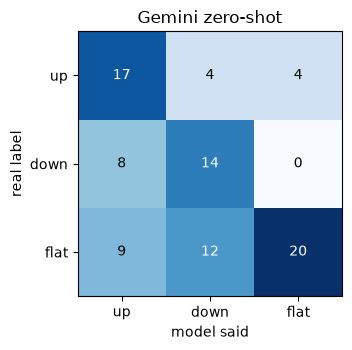


Cost and speed per setting (paid rates, $0 on the free tier):
                         calls  avg_in_tokens  total_cost_usd  median_ms
setting                                                                 
Gemini zero-shot            88       827.1705          0.4740    10509.5
Gemini few-shot, k = 1      88      2693.1705          0.7535    13303.5
Gemini few-shot, k = 5      88     10522.1705          1.4316    14752.5
Gemini few-shot, k = 10     88     20965.1705          2.2713    18532.5


In [13]:
# Step 12: the results table, the best Gemini confusion matrix, and cost per setting
results = pd.DataFrame(RESULTS).set_index("Model")
results["Invalid answers"] = results["Invalid answers"].astype(object)
results.loc["TF-IDF + logistic regression", "Invalid answers"] = "n/a"
print(results.to_string(), "\n")
results.to_csv("group4_results_table.csv")

llm_rows = results.drop(index="TF-IDF + logistic regression")
best_llm = llm_rows["Macro F1"].astype(float).idxmax()
print("Best Gemini setting by macro F1:", best_llm)
show_confusion(best_llm)

if CALL_LOG:
    log = pd.DataFrame(CALL_LOG)
    cost = log.groupby("setting").agg(calls=("setting", "size"), avg_in_tokens=("in_tok", "mean"),
                                      total_cost_usd=("cost_usd", "sum"),
                                      median_ms=("latency_ms", "median")).reindex(SETTINGS).round(4)
    print("\nCost and speed per setting (paid rates, $0 on the free tier):")
    print(cost.to_string())

## Step 13: The ones the model got wrong (teammates)

This shows the test releases our best Gemini model got wrong. For each one you see the real label, what every model guessed, and the start of the release.

Read at least 10 and decide which one it is:
* **Model wrong:** the release clearly points one way and the model picked something else.
* **Label wrong:** our label from the stock price looks off, or the text isn't really an earnings release.
* **Unclear:** the release could honestly go either way, like strong results but a weak outlook.

Then fill in the table below with one short line for each.

In [14]:
# Step 13: the releases the best Gemini setting got wrong
check = test_df[["record_id", "label", "text"]].copy()
for name, preds in ALL_PREDS.items():
    check[name] = preds
wrong = check[check[best_llm] != check.label]
print(f"{best_llm} got {len(wrong)} of {len(check)} wrong. Showing up to 12:\n")
for _, r in wrong.head(12).iterrows():
    print(f"[{r.record_id}] real label: {r.label}")
    print("   " + " | ".join(f"{n}: {r[n]}" for n in ALL_PREDS))
    print("   " + r.text[:600].replace("\n", " ") + " ...\n")

Gemini zero-shot got 37 of 88 wrong. Showing up to 12:

[R164] real label: flat
   TF-IDF + logistic regression: up | Gemini zero-shot: up | Gemini few-shot, k = 1: up | Gemini few-shot, k = 5: up | Gemini few-shot, k = 10: up
   EXHIBIT 99.1 Press Release FOR IMMEDIATE RELEASE For further information: Chandni Luthra - Investors Steve Iaco - Media 212.984.8113 212.984.6535 Chandni.Luthra@cbre.com Steven.Iaco@cbre.com CBRE GROUP, INC. REPORTS FINANCIAL RESULTS FOR Q1 2026 Dallas – April 23, 2026 — CBRE Group, Inc. (NYSE: CBRE) today reported financial results for the first quarter ended March 31, 2026. Key Highlights: • GAAP EPS up 98% to $1.07 and Core EPS up 81% to $1.61 • Revenue up 19% to $10.5 billion • Resilient Businesses (1) revenue up 18% • Transactional Businesses (1) revenue up 22% • Cash flow from operations ...

[R034] real label: up
   TF-IDF + logistic regression: flat | Gemini zero-shot: flat | Gemini few-shot, k = 1: flat | Gemini few-shot, k = 5: flat | Gemini few-shot

### What we found (12 errors reviewed)

| Record | Real label | Model said | Error type | Why |
|---|---|---|---|---|
| R164 | flat | up | Unclear | CBRE reported 19% revenue growth, 98% GAAP EPS growth, and raised guidance. The positive results supported Up, but the recorded stock movement was Flat. |
| R034 | up | flat | Unclear | MAA reported lower EPS and Core FFO but slightly higher FFO. These mixed results did not clearly suggest a strong positive stock reaction. |
| R125 | flat | up | Unclear | Live Nation reported record concert activity and strong future demand. The positive outlook did not result in stock outperformance greater than 3%. |
| R298 | flat | up | Unclear | Targa reported 18% adjusted EBITDA growth and record volumes but maintained its annual EBITDA outlook. The reaction remained within the Flat range. |
| R085 | up | down | Model wrong | Carnival exceeded guidance, reported record revenue, and projected earnings growth. The release strongly supported a positive prediction rather than Down. |
| R008 | flat | down | Unclear | BXP reported revenue growth but lower FFO that missed guidance. The mixed results could reasonably suggest weakness without guaranteeing a Down reaction. |
| R161 | flat | down | Unclear | Old Dominion reported revenue down 5.8%, operating income down 12.5%, and EPS down 11.2%. The negative results did not produce a relative stock movement beyond the Down range. |
| R002 | up | flat | Label wrong | This CBRE release announced the acquisition of Industrious rather than quarterly earnings results. The record should be reviewed for removal from the earnings dataset. |
| R145 | down | up | Unclear | Estee Lauder reported stronger sales and adjusted earnings while raising guidance. Despite the positive information, the recorded stock reaction was Down. |
| R166 | flat | down | Unclear | Dow reported 6% lower sales, declining volumes, and a GAAP net loss. These negative results did not lead to a relative stock decline greater than 3%. |
| R274 | flat | up | Unclear | Tyson reported improved operating income, but sales were nearly unchanged and adjusted performance was mixed. The recorded reaction was Flat. |
| R174 | up | flat | Unclear | Mondelez reported revenue growth and higher reported EPS, but adjusted EPS declined and volume/mix was negative. The mixed signals made the positive stock reaction difficult to predict. |

**Summary:** We reviewed 12 incorrect zero-shot Gemini predictions. Most were difficult because positive or negative financial results did not necessarily produce a stock movement greater than 3% relative to the S&P 500. R002 also revealed a data-selection issue because it was an acquisition announcement, not an earnings release. These findings suggest that the final project should improve text quality, verify event eligibility, and investigate why earnings sentiment does not consistently predict the stock's reaction.


## Step 14: What it means (teammate)

**Which model did best?** Gemini zero shot performed best at 58% accuracy

**Which label was hardest?** Down was the hardest for the model with a F1 score of 0.538 compared to 0.576 for up and 0.615 flat

**Did more examples help?** No, more examples affected performance negatively

**What did it cost?** 4.93 usd

**What we'll change for the final project:**
1. Expand the dataset
2. remove announcements unrelated to earnings
3. verify stock price dates
4. include a human baseline and a more detailed cost analysis


## Step 15: Save the files (Nabeel)


In [15]:
# Step 15: save everything and download it
pd.DataFrame(CALL_LOG).to_csv(LOG_FILE, index=False)
check.to_csv("group4_test_predictions_all_models.csv", index=False)
out = [PRED_FILE, LOG_FILE, "group4_results_table.csv", "group4_split_ids.csv",
       "group4_test_predictions_all_models.csv"]
print(f"{len(CALL_LOG)} Gemini calls logged, ${spent():.4f} at paid rates.")
try:
    from google.colab import files
    for f in out:
        files.download(f)
except ImportError:
    print("Not in Colab. Files are in", os.getcwd())

352 Gemini calls logged, $4.9304 at paid rates.
Not in Colab. Files are in /private/tmp/claude-501/-Users-mnabeel/63a378e9-55c5-4203-be71-bef86bce0eb2/scratchpad/i367/run
